# Explore

Results reported in the paper.

Run the experiments first (`scripts/run_all.sh`).
The notebook reads the results from `../results`.

In [ ]:
import json
import random
import sys
from difflib import SequenceMatcher
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu

sys.path.append('..')
from src.vocabulary import build_vocabulary

In [2]:
RESULTS = Path('../results')
SEARCH_WIDTH = {'greedy': 256, 'baseline': 1}
TASKS = ['fp', 'fn']
MODEL_NAMES = {
    'Qwen2.5-7B-Instruct': 'Qwen-7B',
    'Qwen2.5-14B-Instruct': 'Qwen-14B',
    'Qwen2.5-32B-Instruct': 'Qwen-32B',
    'Llama-3.1-8B-Instruct': 'Llama-8B',
    'Mistral-Small-24B-Instruct-2501': 'Mistral-Small-24B',
}

In [3]:
random.seed(0)

## Loading, thinking, picturing, pondering, fathoming, sleuthing ...

In [4]:
# one row per search run
rows = []
for path in RESULTS.glob('*/model=*/prompt=*/n-permutations=*/seed=*.json'):
    method, *params = path.relative_to(RESULTS).with_suffix('').parts
    if method not in SEARCH_WIDTH:
        continue
    run = dict(param.split('=', 1) for param in params)
    data = json.loads(path.read_text())
    steps = data['steps']
    *word_set, query = steps[-1]['words']

    rows.append({
        'method': method,
        'model': MODEL_NAMES[run['model'].split('--')[-1]],
        'task': 'fp' if '_fp_' in run['prompt'] else 'fn',
        'n_permutations': int(run['n-permutations']),
        'seed': int(run['seed']),
        'steps': len(steps) - 1,
        'query': query,
        'set': tuple(word_set),
        'success': steps[-1]['success'],
        'n_success': data['permutations']['n_success']
    })

runs = pd.DataFrame(rows)
runs['queries'] = runs['steps'] * runs['method'].map(SEARCH_WIDTH) * runs['n_permutations']
runs['task'] = pd.Categorical(runs['task'], categories=TASKS, ordered=True)
runs['model'] = pd.Categorical(runs['model'], categories=MODEL_NAMES.values(), ordered=True)

## Search results

- number of successful runs out of 20
- mean and population std over successful runs
    - number of model evaluations (in thousands)
    - fooled orderings (out of 24)

In [5]:
# steps and queries averaged over successful runs
summary = (
    runs.assign(
        steps=runs['steps'].where(runs['success']),
        evals=runs['queries'].where(runs['success']) / 1000,
        perms=runs['n_success'].where(runs['success'])
    )
    .groupby(['task', 'model', 'method', 'n_permutations'], observed=True)
    .agg(
        runs=('seed', 'size'),
        success=('success', 'sum'),
        steps_mean=('steps', 'mean'),
        steps_std=('steps', lambda s: s.std(ddof=0)),
        evals_mean=('evals', 'mean'),
        evals_std=('evals', lambda s: s.std(ddof=0)),
        perms_mean=('perms', 'mean'),
        perms_std=('perms', lambda s: s.std(ddof=0))
    )
)

with pd.option_context('display.max_rows', None):
    display(summary.round(1))

runs  success  steps_mean  \
task model             method   n_permutations                              
fp   Qwen-7B           baseline 1                 20        0         NaN   
                       greedy   1                 20       16        30.4   
                                4                 20       13        46.7   
     Qwen-14B          baseline 1                 20        1      2779.0   
                       greedy   1                 20       15        28.2   
                                4                 20       17        34.5   
     Qwen-32B          baseline 1                 20        0         NaN   
                       greedy   1                 20       20        14.8   
                                4                 20       19        17.1   
     Llama-8B          baseline 1                 20        2     17179.5   
                       greedy   1                 20       20        19.8   
                                4                 20       20        33.6   
     Mistral-Small-24B baseline 1                 20        2     11214.5   
                       greedy   1                 20       20        16.8   
                                4                 20       20        13.4   
fn   Qwen-7B           baseline 1                 20       20      6121.0   
                       greedy   1                 20       20         6.2   
                                4                 20       20        10.8   
     Qwen-14B          baseline 1                 20       15      9005.0   
                       greedy   1                 20       20        15.1   
                                4                 20       15        22.5   
     Qwen-32B          baseline 1                 20       18      8158.3   
                       greedy   1                 20       17        20.2   
                                4                 20       16        26.4   
     Llama-8B          baseline 1                 20        0         NaN   
                       greedy   1                 20       16        21.3   
                                4                 20       12        29.3   
     Mistral-Small-24B baseline 1                 20        0         NaN   
                       greedy   1                 20        1        40.0   
                                4                 20        0         NaN   

                                                steps_std  evals_mean  \
task model             method   n_permutations                          
fp   Qwen-7B           baseline 1                     NaN         NaN   
                       greedy   1                    24.1         7.8   
                                4                    27.9        47.8   
     Qwen-14B          baseline 1                     0.0         2.8   
                       greedy   1                    23.1         7.2   
                                4                    24.2        35.4   
     Qwen-32B          baseline 1                     NaN         NaN   
                       greedy   1                    14.8         3.8   
                                4                    14.9        17.5   
     Llama-8B          baseline 1                  2469.5        17.2   
                       greedy   1                    13.3         5.1   
                                4                    28.7        34.4   
     Mistral-Small-24B baseline 1                  8434.5        11.2   
                       greedy   1                    14.2         4.3   
                                4                    10.5        13.8   
fn   Qwen-7B           baseline 1                  4990.0         6.1   
                       greedy   1                     4.8         1.6   
                                4                     7.6        11.1   
     Qwen-14B          baseline 1                  6151.4         9.0   
                       greedy   1                 

### Search: greedy vs. baseline

In [6]:
# failed run costs infinite queries
p1 = runs.query('n_permutations == 1')

cost = (
    p1.assign(
        cost=p1['queries'].astype(float).where(p1['success'], np.inf)
    )
    .pivot(
        index=['task', 'model', 'seed'],
        columns='method',
        values='cost'
    )
)

pd.DataFrame({
    'baseline_faster': cost['baseline'] < cost['greedy'],
    'greedy_faster': cost['greedy'] < cost['baseline']
}).groupby(['task', 'model'], observed=True).sum()

baseline_faster  greedy_faster
task model                                            
fp   Qwen-7B                          0             16
     Qwen-14B                         0             15
     Qwen-32B                         0             20
     Llama-8B                         0             20
     Mistral-Small-24B                1             19
fn   Qwen-7B                          3             17
     Qwen-14B                         4             16
     Qwen-32B                         7             11
     Llama-8B                         0             16
     Mistral-Small-24B                0              1

### Permutations: K=1 vs. K=4

In [7]:
# which setting fools more orderings
# only seeds where both K=1 and K=4 succeeded
greedy = runs.query("method == 'greedy'")
n_success = greedy.pivot(
    index=['task', 'model', 'seed'],
    columns='n_permutations',
    values='n_success')
success = greedy.pivot(
    index=['task', 'model', 'seed'],
    columns='n_permutations',
    values='success')
both = success[1] & success[4]

pd.DataFrame({
    'both_successful': both,
    'p1_better': both & (n_success[1] > n_success[4]),
    'p4_better': both & (n_success[4] > n_success[1]),
}).groupby(['task', 'model'], observed=True).sum()

both_successful  p1_better  p4_better
task model                                                   
fp   Qwen-7B                         11          2          8
     Qwen-14B                        13          2         10
     Qwen-32B                        19          4         12
     Llama-8B                        20          3         15
     Mistral-Small-24B               20          4         15
fn   Qwen-7B                         20          2         16
     Qwen-14B                        15          3         12
     Qwen-32B                        13          1         11
     Llama-8B                        10          1          8
     Mistral-Small-24B                0          0          0

## Similarity of the query to the set words

gestalt similarity of the query and the most similar other set word
- for random sets (null hypothesis)
- for the errors found by greedy

In [8]:
def similarity(query, words):
    # compare only to different words from query
    other_words = [word for word in words if word != query]
    # Gestalt pattern matching to the most similar word
    ratios = [SequenceMatcher(None, query, word).ratio() for word in other_words]
    return max(ratios)

In [9]:
def is_substring(query, words):
    other_words = [word for word in words if word != query]
    return any(query in word or word in query for word in other_words)

In [10]:
# errors found by greedy search (distinct word sets)
errors = runs.query("method == 'greedy' and success").copy()
errors = errors.drop_duplicates(['task', 'model', 'query', 'set'])
errors['similarity'] = list(map(similarity, errors['query'], errors['set']))

# null hypothesis: 10,000 random sets
# FP: query and 4 set words
# FN: query and 3 other set words
vocabulary = build_vocabulary()
random_sets = {}
reference = {}
for task, n_words in [('fp', 5), ('fn', 4)]:
    samples = [random.sample(vocabulary, n_words) for _ in range(10000)]
    random_sets[task] = samples
    similarities = [similarity(query, words) for query, *words in samples]
    reference[task] = pd.Series(similarities)

In [11]:
# mean similarity and share of queries that are a substring of a set word
errors['substring'] = list(map(is_substring, errors['query'], errors['set']))

for task in TASKS:
    task_errors = errors.query('task == @task').sort_values('model')
    task_reference = pd.DataFrame({
        'similarity': reference[task],
        'substring': [is_substring(query, words) for query, *words in random_sets[task]],
    })

    pooled = pd.concat([
        task_errors,
        task_errors.assign(model='all models'),
        task_reference.assign(model='random sets'),
    ])

    task_summary = pooled.groupby('model', sort=False).agg(
        errors=('similarity', 'size'),
        similarity_mean=('similarity', 'mean'),
        similarity_std=('similarity', 'std'),
        substring=('substring', 'mean'),
    )
    print(task.upper())
    display(task_summary.round(2))

FP


,errors,similarity_mean,similarity_std,substring
model,,,,
Qwen-7B,29,0.61,0.20,0.38
Qwen-14B,32,0.55,0.13,0.25
Qwen-32B,37,0.58,0.11,0.27
Llama-8B,40,0.64,0.15,0.22
Mistral-Small-24B,40,0.63,0.13,0.30
all models,178,0.60,0.15,0.28
random sets,10000,0.37,0.10,0.00


FN


,errors,similarity_mean,similarity_std,substring
model,,,,
Qwen-7B,39,0.39,0.16,0.03
Qwen-14B,35,0.33,0.17,0.00
Qwen-32B,32,0.37,0.12,0.00
Llama-8B,28,0.45,0.26,0.18
Mistral-Small-24B,1,0.15,NaN,0.00
all models,135,0.38,0.19,0.04
random sets,10000,0.34,0.11,0.00


In [12]:
# Mann-Whitney U test of found errors vs random sets
# p_greater: probability that a found error is more similar than a random set
# 0.5: no difference
rows = []
for (task, model), group in errors.groupby(['task', 'model'], observed=True):
    test = mannwhitneyu(
        x=group['similarity'],
        y=reference[task],
        alternative='two-sided'
    )
    rows.append({
        'task': task,
        'model': model,
        'errors': len(group),
        'median': group['similarity'].median(),
        'random_median': reference[task].median(),
        'p_greater': test.statistic / (len(group) * len(reference[task])),
        'p_value': test.pvalue,
    })

tests = pd.DataFrame(rows).set_index(['task', 'model'])

# Bonferroni correction for one test per task and model
tests['p_bonferroni'] = (tests['p_value'] * len(tests)).clip(upper=1)
tests.style.format({
    'median': '{:.2f}',
    'random_median': '{:.2f}',
    'p_greater': '{:.2f}',
    'p_value': '{:.1e}',
    'p_bonferroni': '{:.1e}',
})

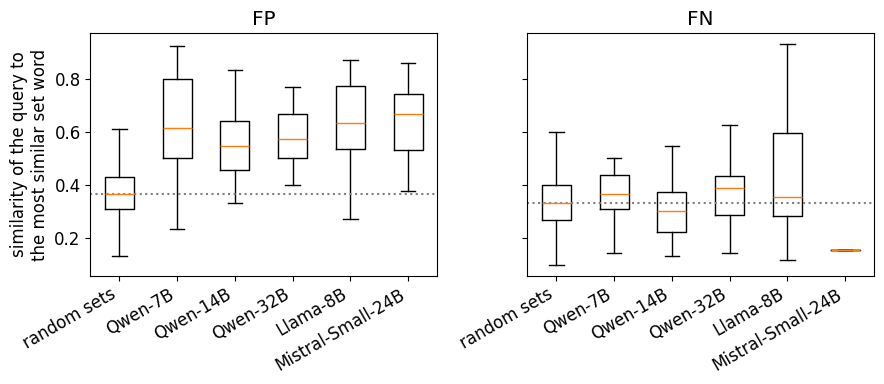

In [13]:
plt.rcParams.update({'font.size': 12})

fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharey=True)
for ax, task in zip(axes, TASKS):
    data = [reference[task]]
    labels = ['random sets']
    for model in MODEL_NAMES.values():
        data.append(errors.query('task == @task and model == @model')['similarity'])
        labels.append(model)

    ax.boxplot(data, showfliers=False)
    ax.axhline(reference[task].median(), color='gray', linestyle=':')
    ax.set_xticks(range(1, len(labels) + 1), labels, rotation=30, ha='right')
    ax.set_title(task.upper())

axes[0].set_ylabel('similarity of the query to\nthe most similar set word')
plt.tight_layout()
plt.show()

### Least and most similar FP errors

In [14]:
# least and most similar FP errors
fp_errors = errors.query("task == 'fp'").sort_values('similarity')
columns = ['model', 'query', 'set', 'similarity', 'substring']

with pd.option_context('display.max_rows', None, 'display.max_colwidth', 100):
    display(fp_errors[columns].head(15).round(3))
    display(fp_errors[columns].tail(15).round(3))

,model,query,set,similarity,substring
235,Qwen-7B,anything,"(electrode, indictment, allegedly, salad)",0.235,False
211,Qwen-7B,incorrectly,"(neighborhood, shabby, dhabi, nephew)",0.261,False
319,Llama-8B,individually,"(diagnostic, madden, identification, radar)",0.273,False
293,Llama-8B,burglary,"(arbitrarily, arabic, myspace, silver)",0.316,False
70,Qwen-14B,enter,"(totalitarian, predominantly, verification, superintendent)",0.333,False
200,Qwen-7B,dhabi,"(indispensable, helper, identification, receive)",0.333,False
51,Qwen-14B,crete,"(multiplication, subcommittee, intercourse, interestingly)",0.353,False
72,Qwen-14B,strap,"(unparalleled, independently, architectural, disadvantage)",0.353,False
389,Mistral-Small-24B,garde,"(archaeology, cafeteria, overwhelmingly, childhood)",0.375,False
233,Qwen-7B,derogatory,"(filmmaker, transgender, scumbag, bakery)",0.375,False


,model,query,set,similarity,substring
298,Llama-8B,produce,"(productive, pancake, neuroscience, providence)",0.824,False
284,Llama-8B,effect,"(defect, conventional, marxist, vowel)",0.833,False
206,Qwen-7B,hanna,"(randy, authentication, rihanna, announcement)",0.833,True
201,Qwen-7B,later,"(platter, contamination, waiter, churchill)",0.833,False
216,Qwen-7B,trail,"(trainer, trailer, cafeteria, spiritually)",0.833,True
218,Qwen-7B,spice,"(lillian, hospice, accomplice, despicable)",0.833,True
286,Llama-8B,forget,"(first, foremost, zelda, forgot)",0.833,False
65,Qwen-14B,bound,"(abundance, rebound, geographically, neighborhood)",0.833,True
399,Mistral-Small-24B,rican,"(african, clandestine, mathematician, scare)",0.833,True
312,Llama-8B,pathetic,"(empathy, sympathetic, handgun, liter)",0.842,True


## False negative query words

most frequent query words of the FN errors found by greedy search
- K=1 and K=4 pooled

In [15]:
def top_words(queries, n=4):
    # most frequent first, ties in alphabetical order
    counts = queries.value_counts().sort_index()
    counts = counts.sort_values(ascending=False, kind='stable')
    words = [f'{word} ({count})' for word, count in counts.head(n).items()]
    return ', '.join(words)

In [16]:
fn = runs.query("task == 'fn' and method == 'greedy' and success")

words_per_model = fn.groupby('model', observed=True)['query'].agg(
    runs='size',
    unique='nunique',
    top_words=top_words,
)

with pd.option_context('display.max_colwidth', 150):
    display(words_per_model)

,runs,unique,top_words
model,,,
Qwen-7B,40,32,"belize (3), denise (2), negotiable (2), partridge (2)"
Qwen-14B,35,18,"massachusetts (7), hungary (5), fatally (4), authoritarian (3)"
Qwen-32B,33,10,"ordnance (10), portugal (10), triumphant (3), bieber (2)"
Llama-8B,28,14,"invalid (8), incorrect (4), dominic (3), professional (3)"
Mistral-Small-24B,1,1,comma (1)


In [17]:
# repeated query words: number of runs and of different seeds
# (K=1 and K=4 runs with the same seed start from the same words)
words = fn.groupby(['model', 'query'], observed=True).agg(
    runs=('seed', 'size'),
    seeds=('seed', 'nunique'),
)

repeated_words = words.query('runs > 1')
repeated_words = repeated_words.sort_values(['model', 'runs'], ascending=[True, False])
display(repeated_words)

runs  seeds
model    query                     
Qwen-7B  belize            3      2
         denise            2      2
         negotiable        2      1
         partridge         2      2
         possibly          2      2
         qaeda             2      1
         rosen             2      1
Qwen-14B massachusetts     7      6
         hungary           5      5
         fatally           4      4
         authoritarian     3      2
         warsaw            3      2
Qwen-32B ordnance         10      9
         portugal         10      7
         triumphant        3      3
         bieber            2      1
         brunswick         2      2
         tasmania          2      2
Llama-8B invalid           8      6
         incorrect         4      3
         dominic           3      2
         professional      3      3

## Repeated query words: FP vs. FN

K=1 runs
- every run starts from different words

In [18]:
def repeated(queries):
    # runs whose query word also ended another run
    return int((queries.map(queries.value_counts()) > 1).sum())

In [19]:
found = runs.query("method == 'greedy' and n_permutations == 1 and success")

repeats = found.groupby(['task', 'model'], observed=True)['query'].agg(
    runs='size',
    repeated_runs=repeated,
)
display(repeats)

runs  repeated_runs
task model                                 
fp   Qwen-7B              16              2
     Qwen-14B             15              0
     Qwen-32B             20              0
     Llama-8B             20              0
     Mistral-Small-24B    20              0
fn   Qwen-7B              20              0
     Qwen-14B             20             12
     Qwen-32B             17             14
     Llama-8B             16              7
     Mistral-Small-24B     1              0

In [20]:
totals = repeats.groupby('task', observed=True).sum()
display(totals)

,runs,repeated_runs
task,,
fp,91,2
fn,74,33
